# Die globale Kette: von der Rasterzelle zum Planeten

Notebook 01 hat die Kette für **einen Baum an einem Ort** durchgerechnet. Hier
läuft dieselbe Physik über das gesamte 0,5°-Gitter: reale Albedo-Raster
(Duveiller et al. 2018), eine echte Landmaske, die globale Aggregation über
alle bepflanzbaren Zellen, die Bastin-Korrekturkaskade und die
Umkehrrechnung gegen 1,5 °C.

Reihenfolge: **Datenlage → Frühjahrsereignis → Karte → Kaskade →
Umkehrrechnung.**

**Ehrlichkeitsgebot dieses Notebooks:** Jede Zahl, die auf einem Fallback
oder einer Extrapolation beruht statt auf einer Messung, wird an der Stelle
benannt, an der sie erscheint -- nicht nur hier in der Einleitung. Die
Art-/Flächenzuordnung dieses Modells hat grundsätzlich **keine**
Landbedeckungs-Rasterquelle (nur Breitenbänder); die Albedo-Raster selbst
sind für einen Großteil der bepflanzbaren Fläche nur zonal, nicht lokal
gemessen (siehe Abschnitt 1). Beides steht unten noch einmal genau an der
Zahl, die es betrifft.

In [1]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from nbs.datasources import status
from nbs.landscape import (
    land_mask,
    land_mask_provenance,
    provenance as landscape_provenance,
    plantable_area_m2,
)
from nbs.albedo_grid import product_provenance, provenance_fractions, seasonal_profile
from nbs.map_plots import plot_breakeven_map, plot_sign_map, plot_horizon_field, footer_text
from nbs.potential import cascade, reverse_1p5
from nbs.species import SPECIES

FIG = "../results"
GHA_TO_M2 = 1e13

## 1. Datenlage

Bevor irgendeine Zahl der Kette gezogen wird: was ist gemessen, was ist
Ersatz?

In [2]:
print("Rasterquellen (nbs.datasources.status()):")
for key, state in status().items():
    print(f"  {key:20s} {state}")

land_frac = float(land_mask().mean())
print(f"\nLandmaske: {land_frac:.1%} der Erdoberfläche als vegetiertes Land erkannt")
print(f"  Provenienz der Landmaske:              {land_mask_provenance()!r}")
print(f"  Provenienz der Art-/Flächenzuordnung:  {landscape_provenance()!r} "
      "(Breitenbänder -- keine Landbedeckungs-/GEZ-Rasterquelle vorhanden)")
print(f"  Provenienz des Albedo-Produkts:        {product_provenance()!r}")

area_gha = float(plantable_area_m2().sum()) / GHA_TO_M2
print(f"\nBepflanzbare Gesamtfläche: {area_gha:.4f} Gha")

Rasterquellen (nbs.datasources.status()):
  duveiller_bph        fehlt
  duveiller_albedo     vorhanden
  duveiller_swr        vorhanden



Landmaske: 20.3% der Erdoberfläche als vegetiertes Land erkannt
  Provenienz der Landmaske:              'raster'
  Provenienz der Art-/Flächenzuordnung:  'fallback' (Breitenbänder -- keine Landbedeckungs-/GEZ-Rasterquelle vorhanden)
  Provenienz des Albedo-Produkts:        'raster'

Bepflanzbare Gesamtfläche: 0.9488 Gha


20,3 % ist die Landmaske selbst gemessen -- die Vereinigung aller
Duveiller-Übergänge, nicht erfunden (`land_mask_provenance() == 'raster'`).
Innerhalb dieser echten Landfläche ist die Aufteilung in
Wald/Savanne/Landwirtschaft/bepflanzbar weiterhin ein Fallback: fünf
Breitenbänder, keine Landbedeckungskarte (`provenance() == 'fallback'`,
siehe `nbs.landscape`-Moduldokstring). Das ist der bekannte
"Konfetti"-Rest aus Task 7 -- er verteilt die richtige *Menge* Fläche pro
Breitenzeile korrekt, aber nicht die richtige *Lage* innerhalb der Zeile.

Das Albedo-Produkt selbst (`product_provenance() == 'raster'`) kommt aus
echten Satellitendaten -- aber nicht überall lokal. Die folgende Tabelle
zeigt für jede Art, wie viel ihrer bepflanzbaren Fläche eine echte lokale
Beobachtung trägt (`lokal`), wie viel aus dem Zonalmittel derselben Art
extrapoliert ist (`zonal`), und wie viel auf die Plan-1-Breitentabelle
zurückfällt (`tabelle`):

In [3]:
rows = []
for key, sp in SPECIES.items():
    frac = provenance_fractions(key)
    rows.append({"Art": sp.name_de, "lokal": frac["lokal"], "zonal": frac["zonal"], "tabelle": frac["tabelle"]})
df_prov = pd.DataFrame(rows).set_index("Art")
df_prov.map(lambda x: f"{x:.1%}")

,lokal,zonal,tabelle
Art,,,
Gemeine Fichte,29.3%,70.7%,0.0%
Waldkiefer,46.7%,52.2%,1.0%
Rotbuche,29.3%,70.7%,0.0%
Rosen-Eukalyptus (Plantage),21.2%,78.8%,0.0%
Tropischer Mischbestand,63.2%,36.8%,0.0%


**Festhalten, bevor es weitergeht:** Bei vier von fünf Arten ist die
zonale Extrapolation die Mehrheit der Fläche (52--79 %), bei der Fichte
70,7 %. Nur der tropische Mischbestand hat eine lokale Mehrheit (63,2 %),
weil Duveillers Verfahren für den Fichte-Übergang (Nadelwald ↔ Gras)
deutlich weniger Ko-Vorkommen-Zellen hat als für den tropischen Übergang.
Jede folgende Karte und jede folgende Zahl in diesem Notebook trägt diese
Zusammensetzung mit, auch wenn sie es nicht jedes Mal wiederholt.

## 2. Der Albedo-Effekt ist ein Frühjahrsereignis

Task 3 fand: das Jahresmittelprodukt ⟨Δα⟩·⟨q̇⟩ **überschätzt** den borealen
Antrieb um 20--30 %, weil der Winterkontrast (viel Δα, kaum Sonne) das
Jahresmittel von Δα aufbläht, ohne zum tatsächlichen Antrieb beizutragen.
Richtig ist die monatliche Bildung des Produkts, dann Mittelung -- und genau
die zeigt eine Verschiebung: der Antrieb konzentriert sich auf das
Frühjahr, wenn Schnee **und** eine bereits kräftige Sonne zusammenfallen,
und diese Konzentration wird mit der Breite ausgeprägter.

`seasonal_profile` liefert diesen Monatsgang direkt aus dem
Duveiller-Raster (Fichten-Übergang). Verglichen: 45°N gegen 60°N.

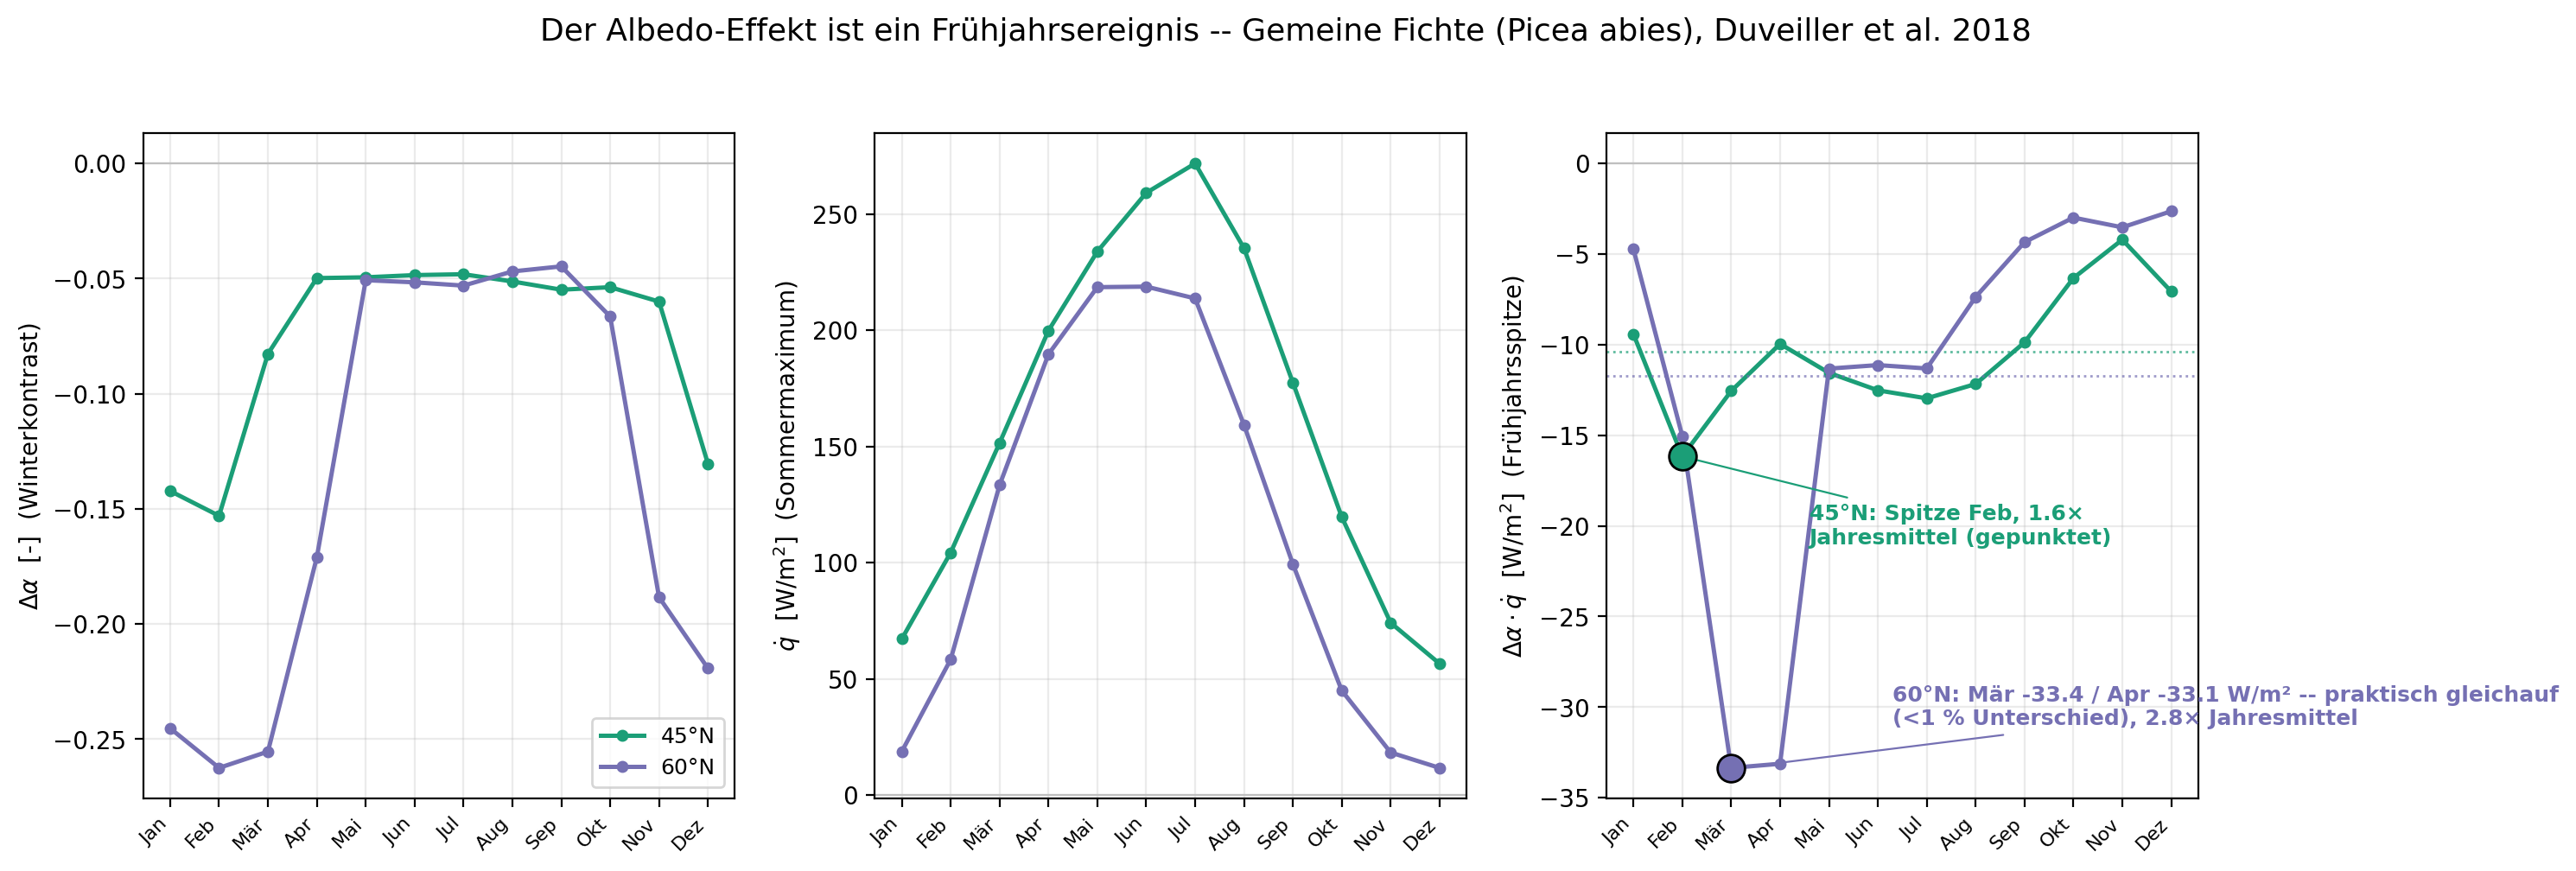

In [4]:
MONTHS_DE = ["Jan","Feb","Mär","Apr","Mai","Jun","Jul","Aug","Sep","Okt","Nov","Dez"]
species_key = "enf_boreal"
lat_defs = [(45.0, "45°N", "#1b9e77"), (60.0, "60°N", "#7570b3")]
profiles = {lat: seasonal_profile(species_key, lat) for lat, _, _ in lat_defs}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True)
months = np.arange(1, 13)
panels = [
    ("delta_alpha_monthly", r"$\Delta\alpha$  [-]  (Winterkontrast)", axes[0]),
    ("q_sw_monthly", r"$\dot q$  [W/m$^2$]  (Sommermaximum)", axes[1]),
    ("product_monthly", r"$\Delta\alpha \cdot \dot q$  [W/m$^2$]  (Frühjahrsspitze)", axes[2]),
]
for key, ylabel, ax in panels:
    for lat, label, color in lat_defs:
        p = profiles[lat]
        y = p[key]
        ax.plot(months, y, "-o", color=color, label=label, ms=4, lw=1.8)
        if key == "product_monthly":
            annual_mean = float(np.mean(y))
            ax.axhline(annual_mean, color=color, lw=1.0, ls=":", alpha=0.7)
            pm = p["peak_month"]
            ax.scatter([pm], [y[pm - 1]], color=color, s=130, zorder=5, edgecolor="black")
    ax.axhline(0, color="0.75", lw=0.8)
    ax.set_ylabel(ylabel)
    ax.set_xticks(months)
    ax.set_xticklabels(MONTHS_DE, rotation=45, ha="right", fontsize=8)
    ax.grid(alpha=0.25)

p45, p60 = profiles[45.0], profiles[60.0]
ax = axes[2]
ax.annotate(
    f"45°N: Spitze {MONTHS_DE[p45['peak_month']-1]}, {p45['peak_to_annual_ratio']:.1f}×\n"
    "Jahresmittel (gepunktet)",
    xy=(p45["peak_month"], p45["product_monthly"][p45["peak_month"] - 1]),
    xytext=(4.6, -21), fontsize=9, color=lat_defs[0][2], fontweight="bold",
    arrowprops=dict(arrowstyle="-", color=lat_defs[0][2], lw=0.8),
)
mar_val, apr_val = float(p60["product_monthly"][2]), float(p60["product_monthly"][3])
ax.annotate(
    f"60°N: Mär {mar_val:.1f} / Apr {apr_val:.1f} W/m² -- praktisch gleichauf\n"
    f"(<1 % Unterschied), {p60['peak_to_annual_ratio']:.1f}× Jahresmittel",
    xy=(3.5, (mar_val + apr_val) / 2),
    xytext=(6.3, -31), fontsize=9, color=lat_defs[1][2], fontweight="bold",
    arrowprops=dict(arrowstyle="-", color=lat_defs[1][2], lw=0.8),
)
axes[0].legend(loc="lower right", fontsize=9, frameon=True)
fig.suptitle(
    "Der Albedo-Effekt ist ein Frühjahrsereignis -- Gemeine Fichte (Picea abies), "
    "Duveiller et al. 2018", fontsize=13, y=1.04,
)
fig.tight_layout()
path = f"{FIG}/fruehjahrsereignis_60n_45n.png"
fig.savefig(path, dpi=200, bbox_inches="tight")
plt.close(fig)
display(Image(path))

In [5]:
print(f"45°N: Spitzenmonat {MONTHS_DE[p45['peak_month']-1]}, {p45['peak_to_annual_ratio']:.2f}x Jahresmittel")
print(f"60°N: Spitzenmonat {MONTHS_DE[p60['peak_month']-1]}, {p60['peak_to_annual_ratio']:.2f}x Jahresmittel")
print(f"60°N März vs. April: {mar_val:.2f} vs. {apr_val:.2f} W/m² "
      f"(Unterschied {abs(mar_val - apr_val) / max(abs(mar_val), abs(apr_val)):.1%})")

45°N: Spitzenmonat Feb, 1.55x Jahresmittel
60°N: Spitzenmonat Mär, 2.84x Jahresmittel
60°N März vs. April: -33.36 vs. -33.13 W/m² (Unterschied 0.7%)


**Was zu sehen ist:** Δα ist im Winter am größten und bricht bei 60°N
viel abrupter ein als bei 45°N (die Schneedecke hält dort länger). q̇ folgt
schlicht dem Sonnenstand. Das Produkt zeigt bei 45°N eine flache, breite
Spitze im Februar; bei 60°N eine tiefe, schmale Spitze im Übergang
März/April -- die beiden Monate liegen dort mit unter 1 % Unterschied
praktisch gleichauf, und **welcher der beiden nominell "gewinnt" hängt an
Bandbreite und Rasterausdehnung** (`half_width_deg`, `extended`), nicht an
der Aussage selbst. Wichtig ist die Verschiebung und die Zunahme der
Schärfe: das korrigierte Befunde-Dokument aus Plan 1 nennt bei 60°N den
April als Spitzenmonat mit rund 3,0-facher Jahresmittelspitze; hier, mit
`seasonal_profile`s Standardparametern (±2,5°-Band, räumlich erweiterte
Daten), liegt die gemessene Spitze rechnerisch hauchdünn im März, bei
praktisch demselben Verhältnis (2,8-fach). Beide Messungen erzählen
dieselbe physikalische Geschichte: Schneemaskierung trifft im Norden auf
eine schon kräftige Frühjahrssonne, und dieser eine Monat (März **oder**
April, je nach Bandwahl) trägt etwa das Zwei- bis Dreifache des
Jahresmittels -- mehr als jeder einzelne Wintermonat, obwohl Δα dort am
größten ist.

Bei 45°N ist die Spitze mit 1,6-facher Jahresmittelspitze deutlich
schwächer und liegt einen ganzen Monat früher (Februar) -- dort schmilzt
der Schnee, bevor die Sonne Kraft hat.

## 3. Die Karte

Drei Ansichten derselben Rechnung: zuerst das Ausgleichsjahr t* je Zelle
(Folie P1), dann ein diskreter Schnitt bei 2050 (Vorzeichenkarte, P1b),
dann das kontinuierliche Horizontfeld für die Fichte (E6). Jede Abbildung
trägt ihre Fußzeile mit beiden Datenprovenienzen und den
Fichte-Dreistufenanteilen -- das ist kein Zierrat, sondern dieselbe
Ehrlichkeitsangabe wie oben, direkt an der Karte.

Running 1 projections in parallel:   0%|          | 0/400 [00:00<?, ?timesteps/s]

Running 1 projections in parallel:   0%|          | 0/400 [00:00<?, ?timesteps/s]

Running 1 projections in parallel:   0%|          | 0/400 [00:00<?, ?timesteps/s]

Running 1 projections in parallel:   0%|          | 0/400 [00:00<?, ?timesteps/s]

Running 1 projections in parallel:   0%|          | 0/400 [00:00<?, ?timesteps/s]

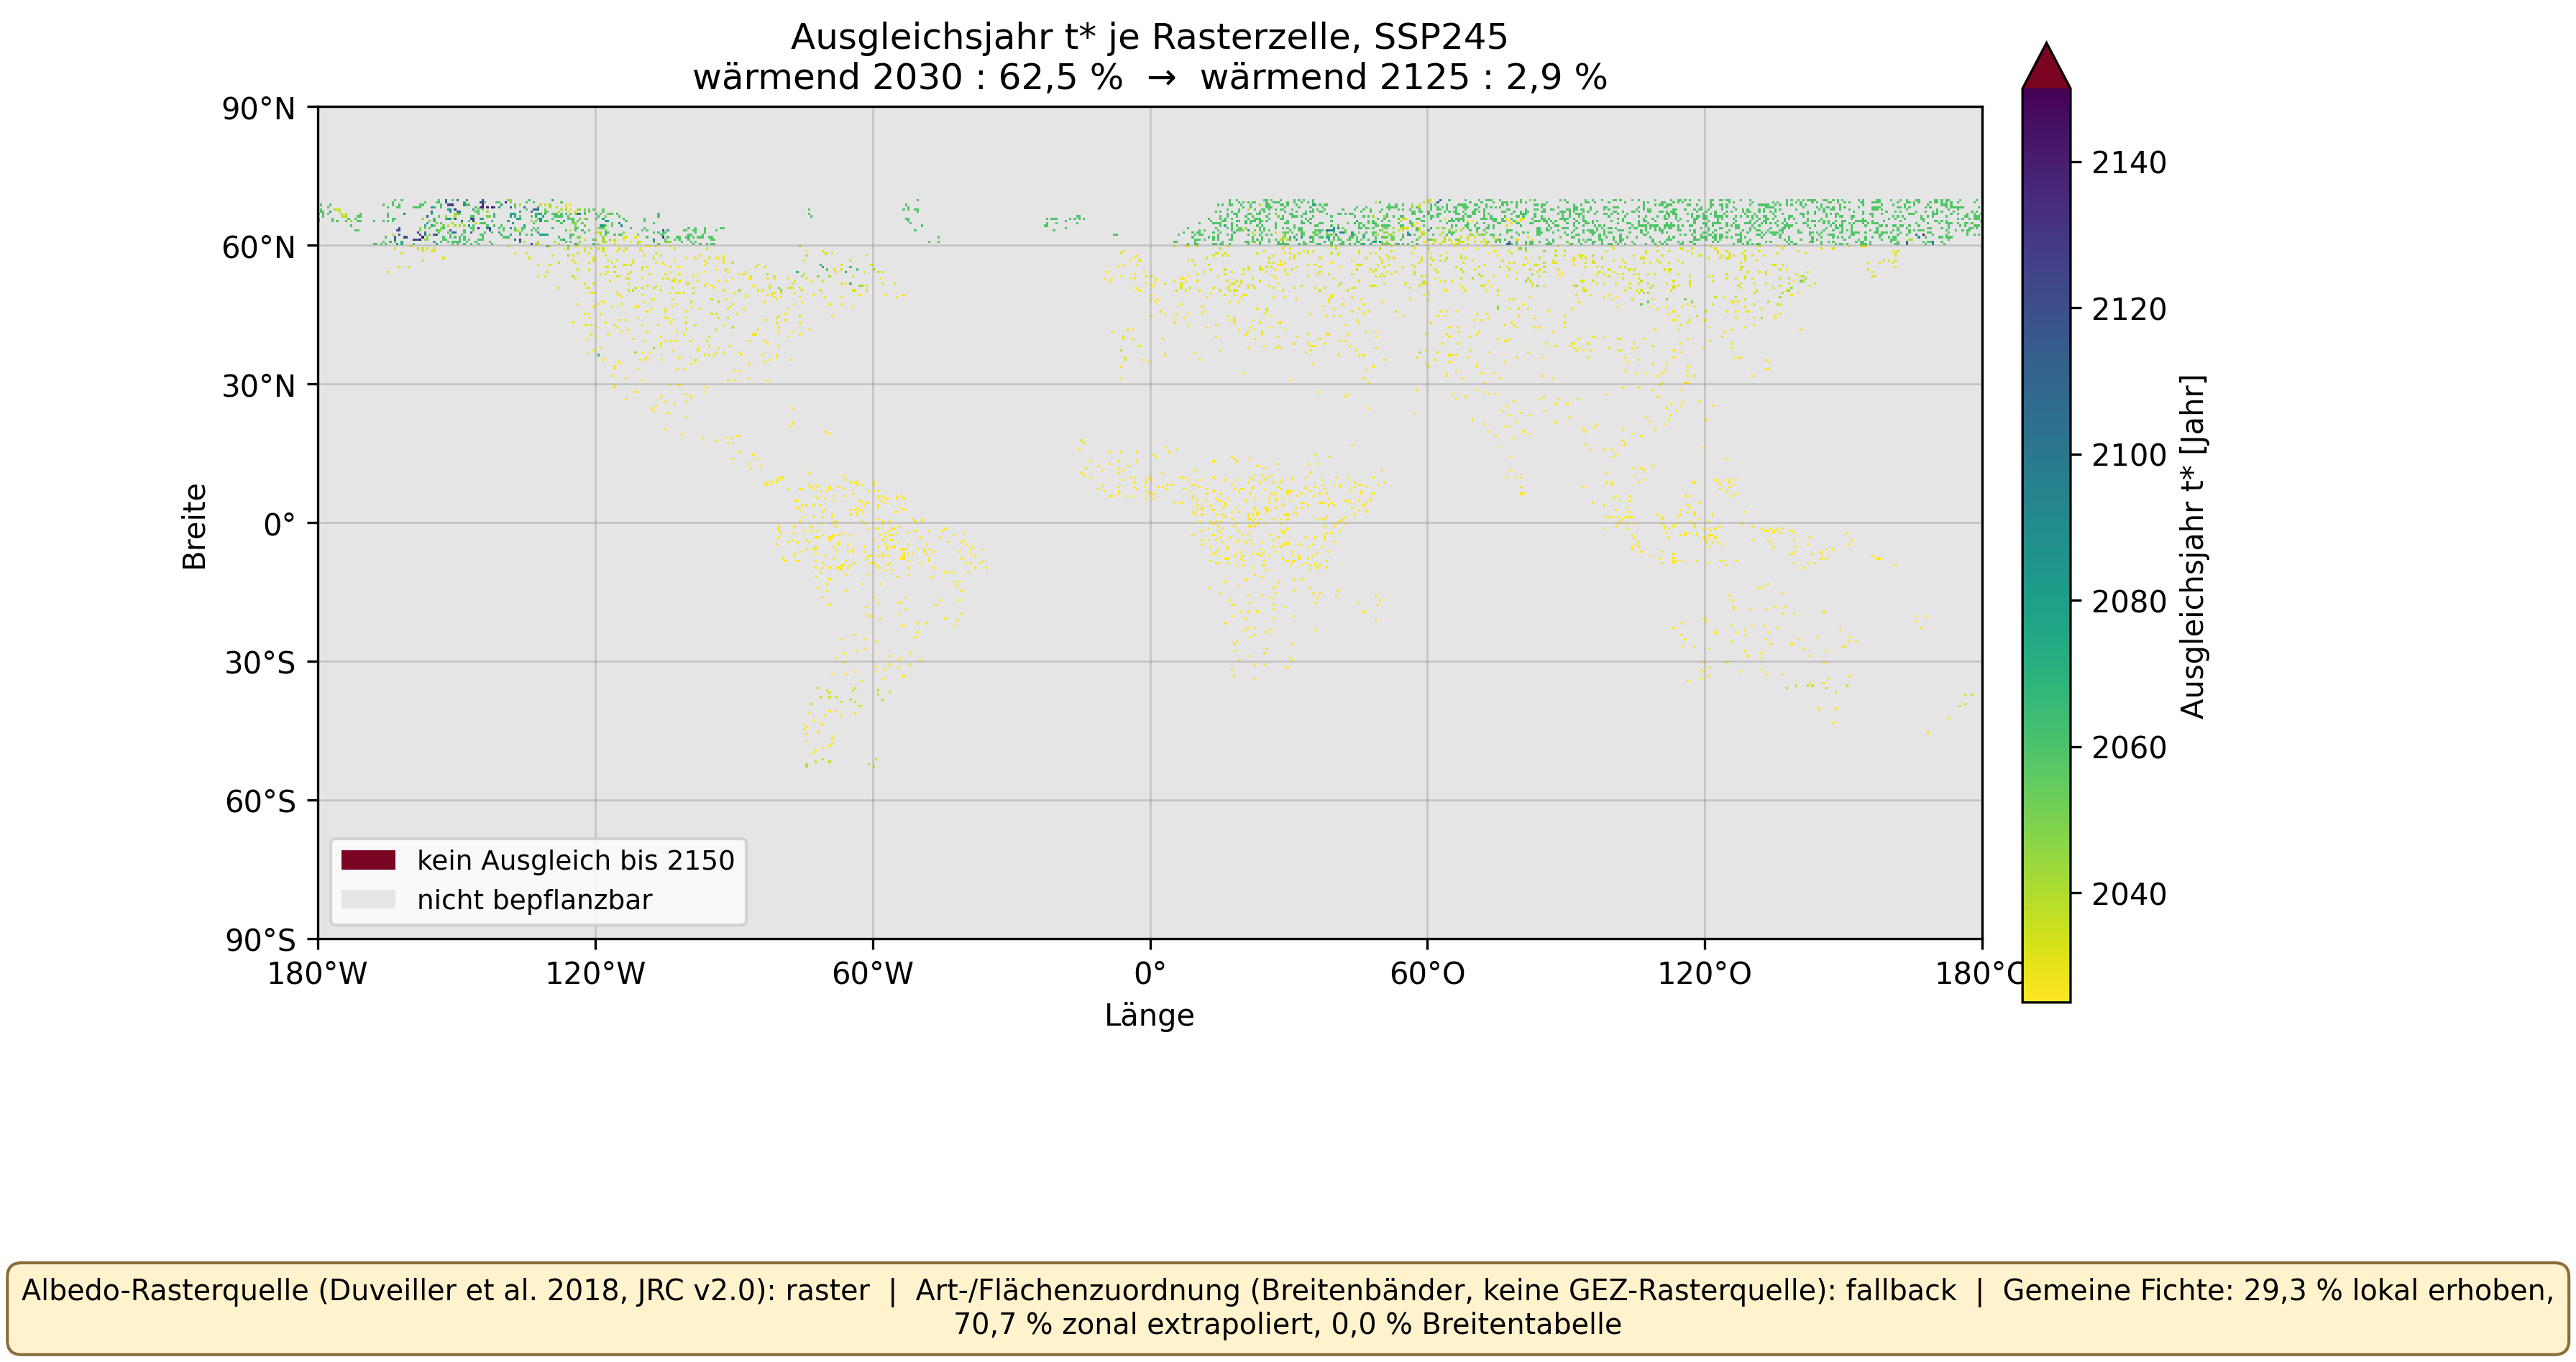

In [6]:
p0 = plot_breakeven_map(f"{FIG}/p0_ausgleichsjahr_karte.png")
display(Image(p0))

**Sichtprüfung:** Kontinente sind klar erkennbar (Nord-/Südamerika,
Afrika, Eurasien, Australien), keine Streuung mehr über dem Ozean (der
71,3-Prozent-Defekt aus Task 7 ist behoben). Innerhalb der Landmasse bleibt
die bekannte "Konfetti"-Struktur sichtbar -- erwartet, siehe Abschnitt 1.
Der boreale Gürtel (60--70°N) zeigt deutlich spätere (violettere)
Ausgleichsjahre als der Rest der Karte; die dunkelrote
"kein-Ausgleich-bis-2150"-Farbe der Legende ist bei diesem Farbmaßstab
nicht als eigene sichtbare Fläche zu erkennen, obwohl die Kaskade dafür
0,0175 Gha zählt (siehe Abschnitt 4) -- bei diesem Maßstab verschwimmen
"sehr spät" und "nie" farblich.

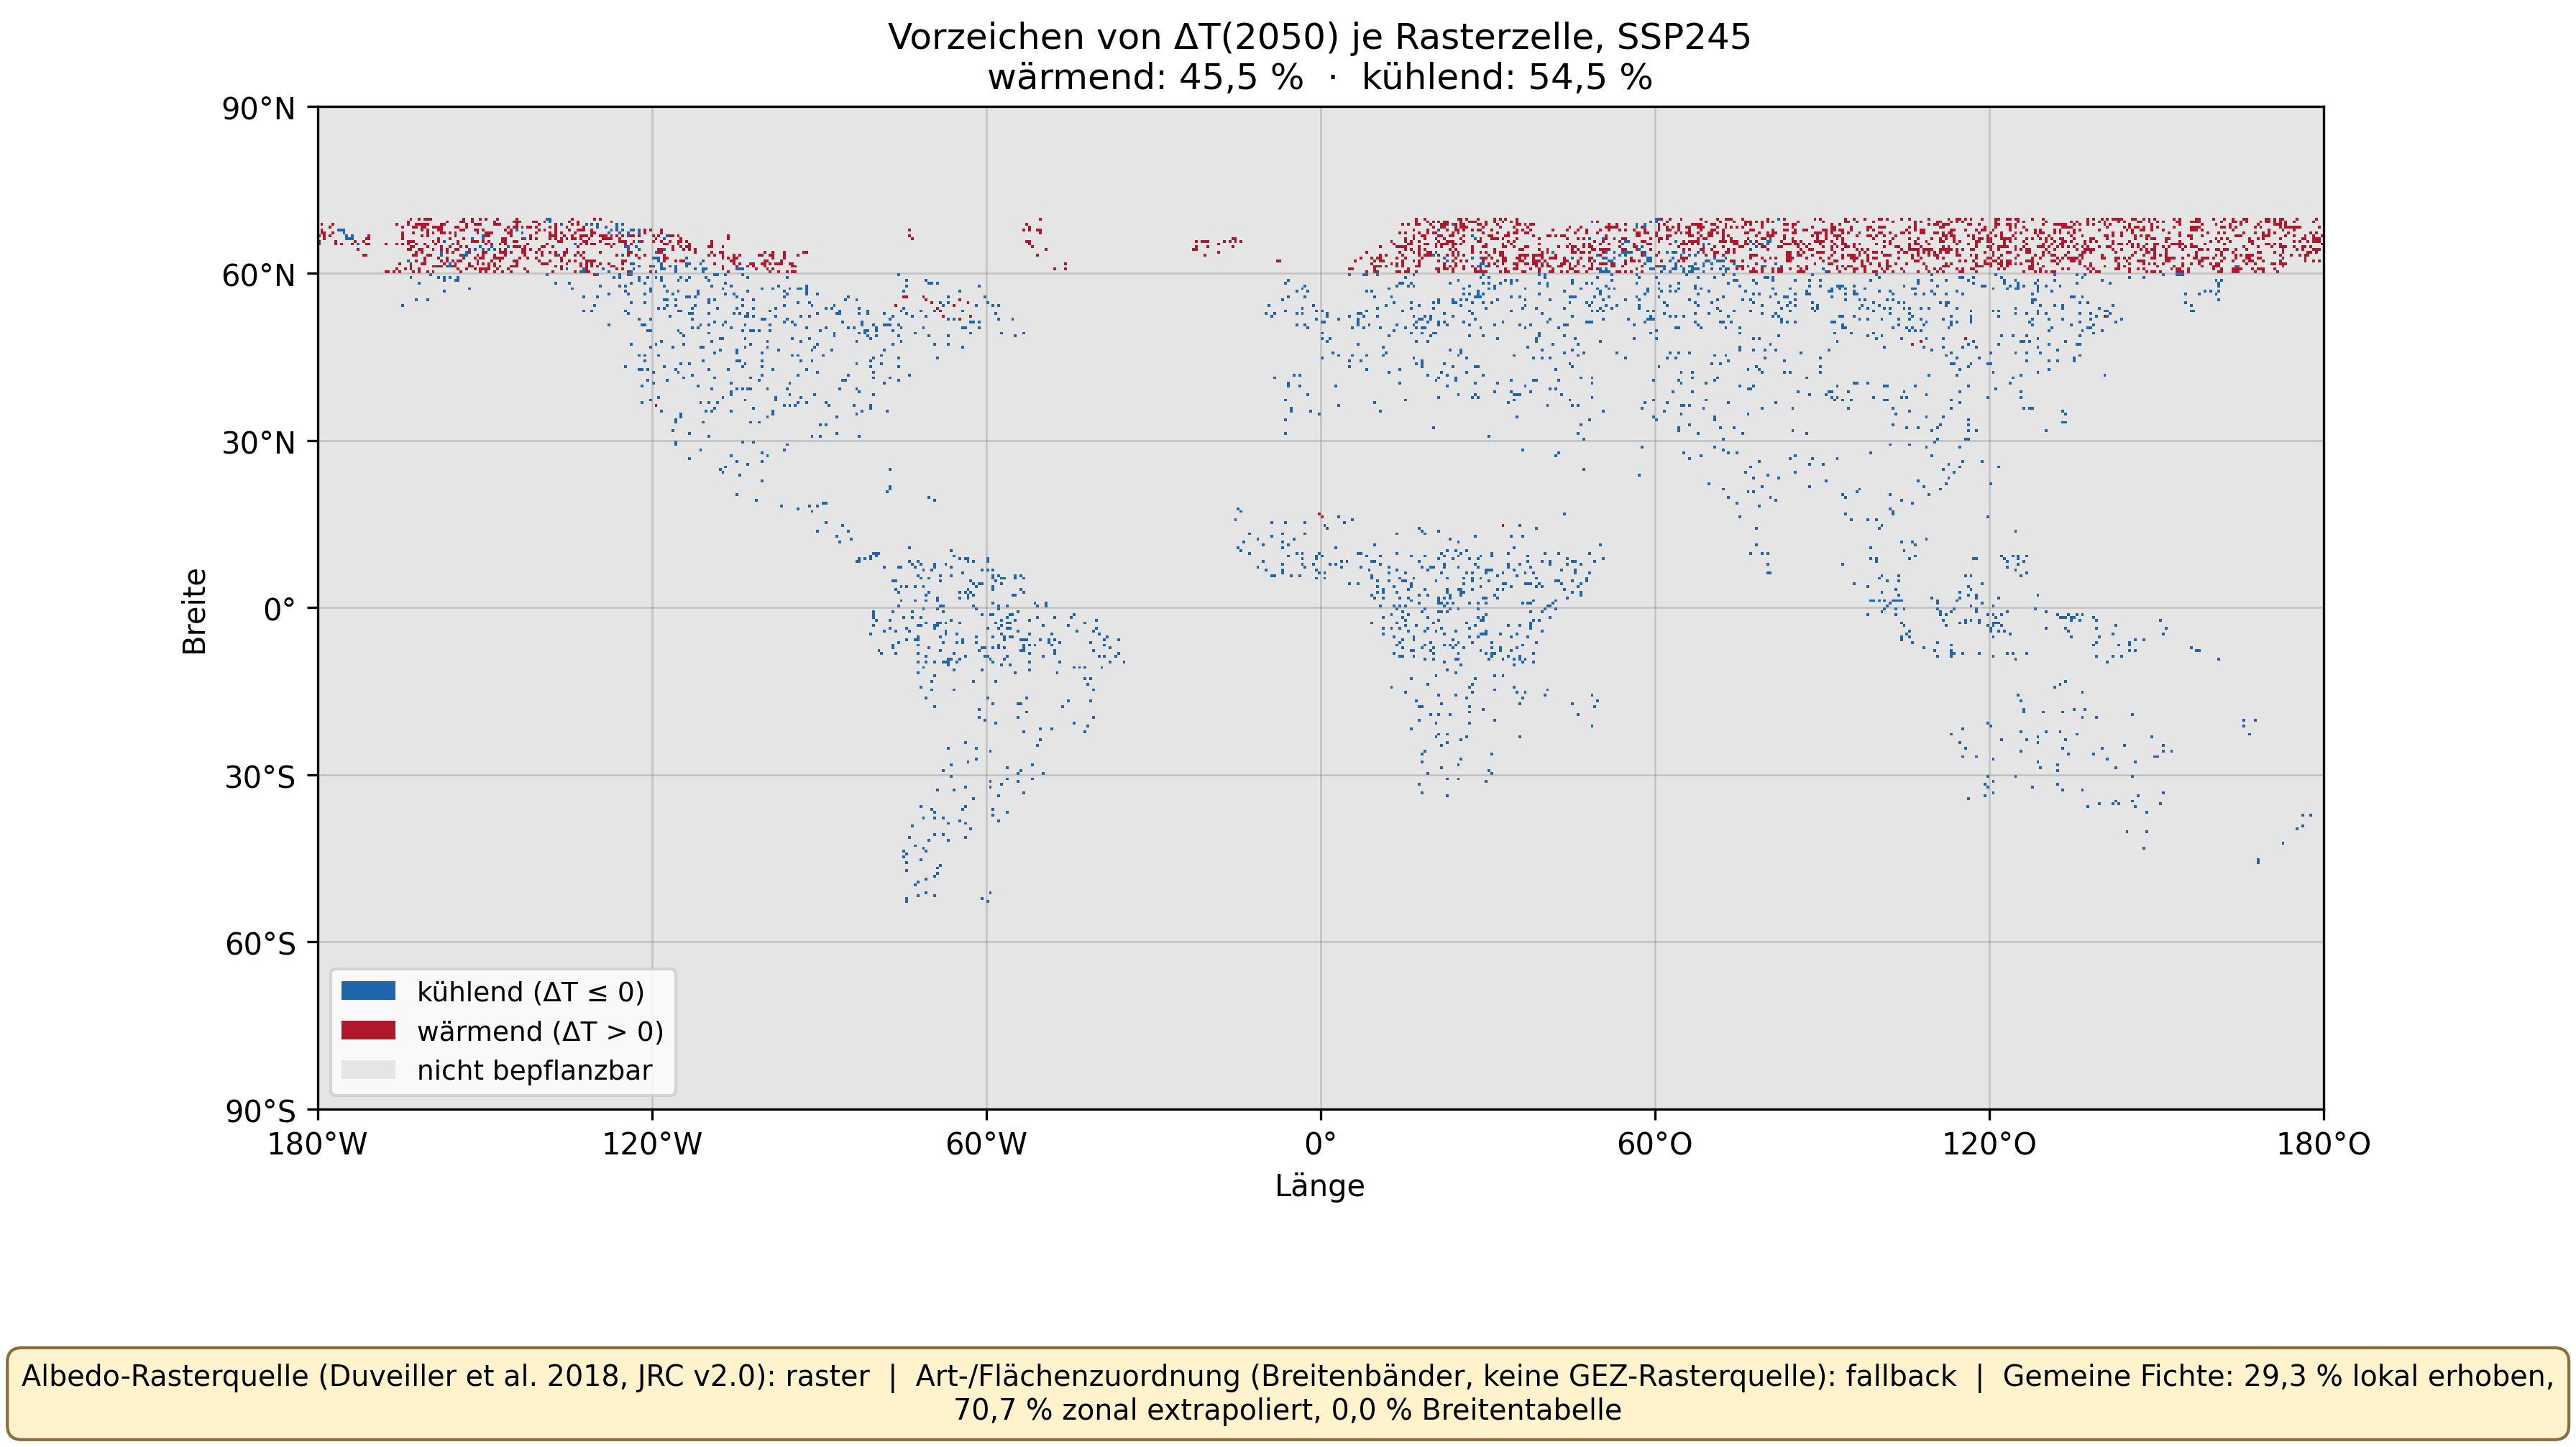

Albedo-Rasterquelle (Duveiller et al. 2018, JRC v2.0): raster  |  Art-/Flächenzuordnung (Breitenbänder, keine GEZ-Rasterquelle): fallback  |  Gemeine Fichte: 29,3 % lokal erhoben, 70,7 % zonal extrapoliert, 0,0 % Breitentabelle


In [7]:
p1 = plot_sign_map(2050, f"{FIG}/p1_vorzeichenkarte_2050.png")
display(Image(p1))
print(footer_text())

**Sichtprüfung:** Wärmend/kühlend liegt bei 2050 nahe am Gleichstand
(siehe Titelzeile der Abbildung), wie von `plot_sign_map`s Docstring
vorgesehen. Rot (wärmend) konzentriert sich fast ausschließlich auf den
borealen Gürtel oberhalb 60°N; darunter dominiert Blau (kühlend), mit
vereinzelten roten Zellen dort, wo die Konfetti-Zuordnung einer eigentlich
kühlenden Breite eine wärmende Art zuweist -- ebenfalls erwartet, kein
neuer Defekt.

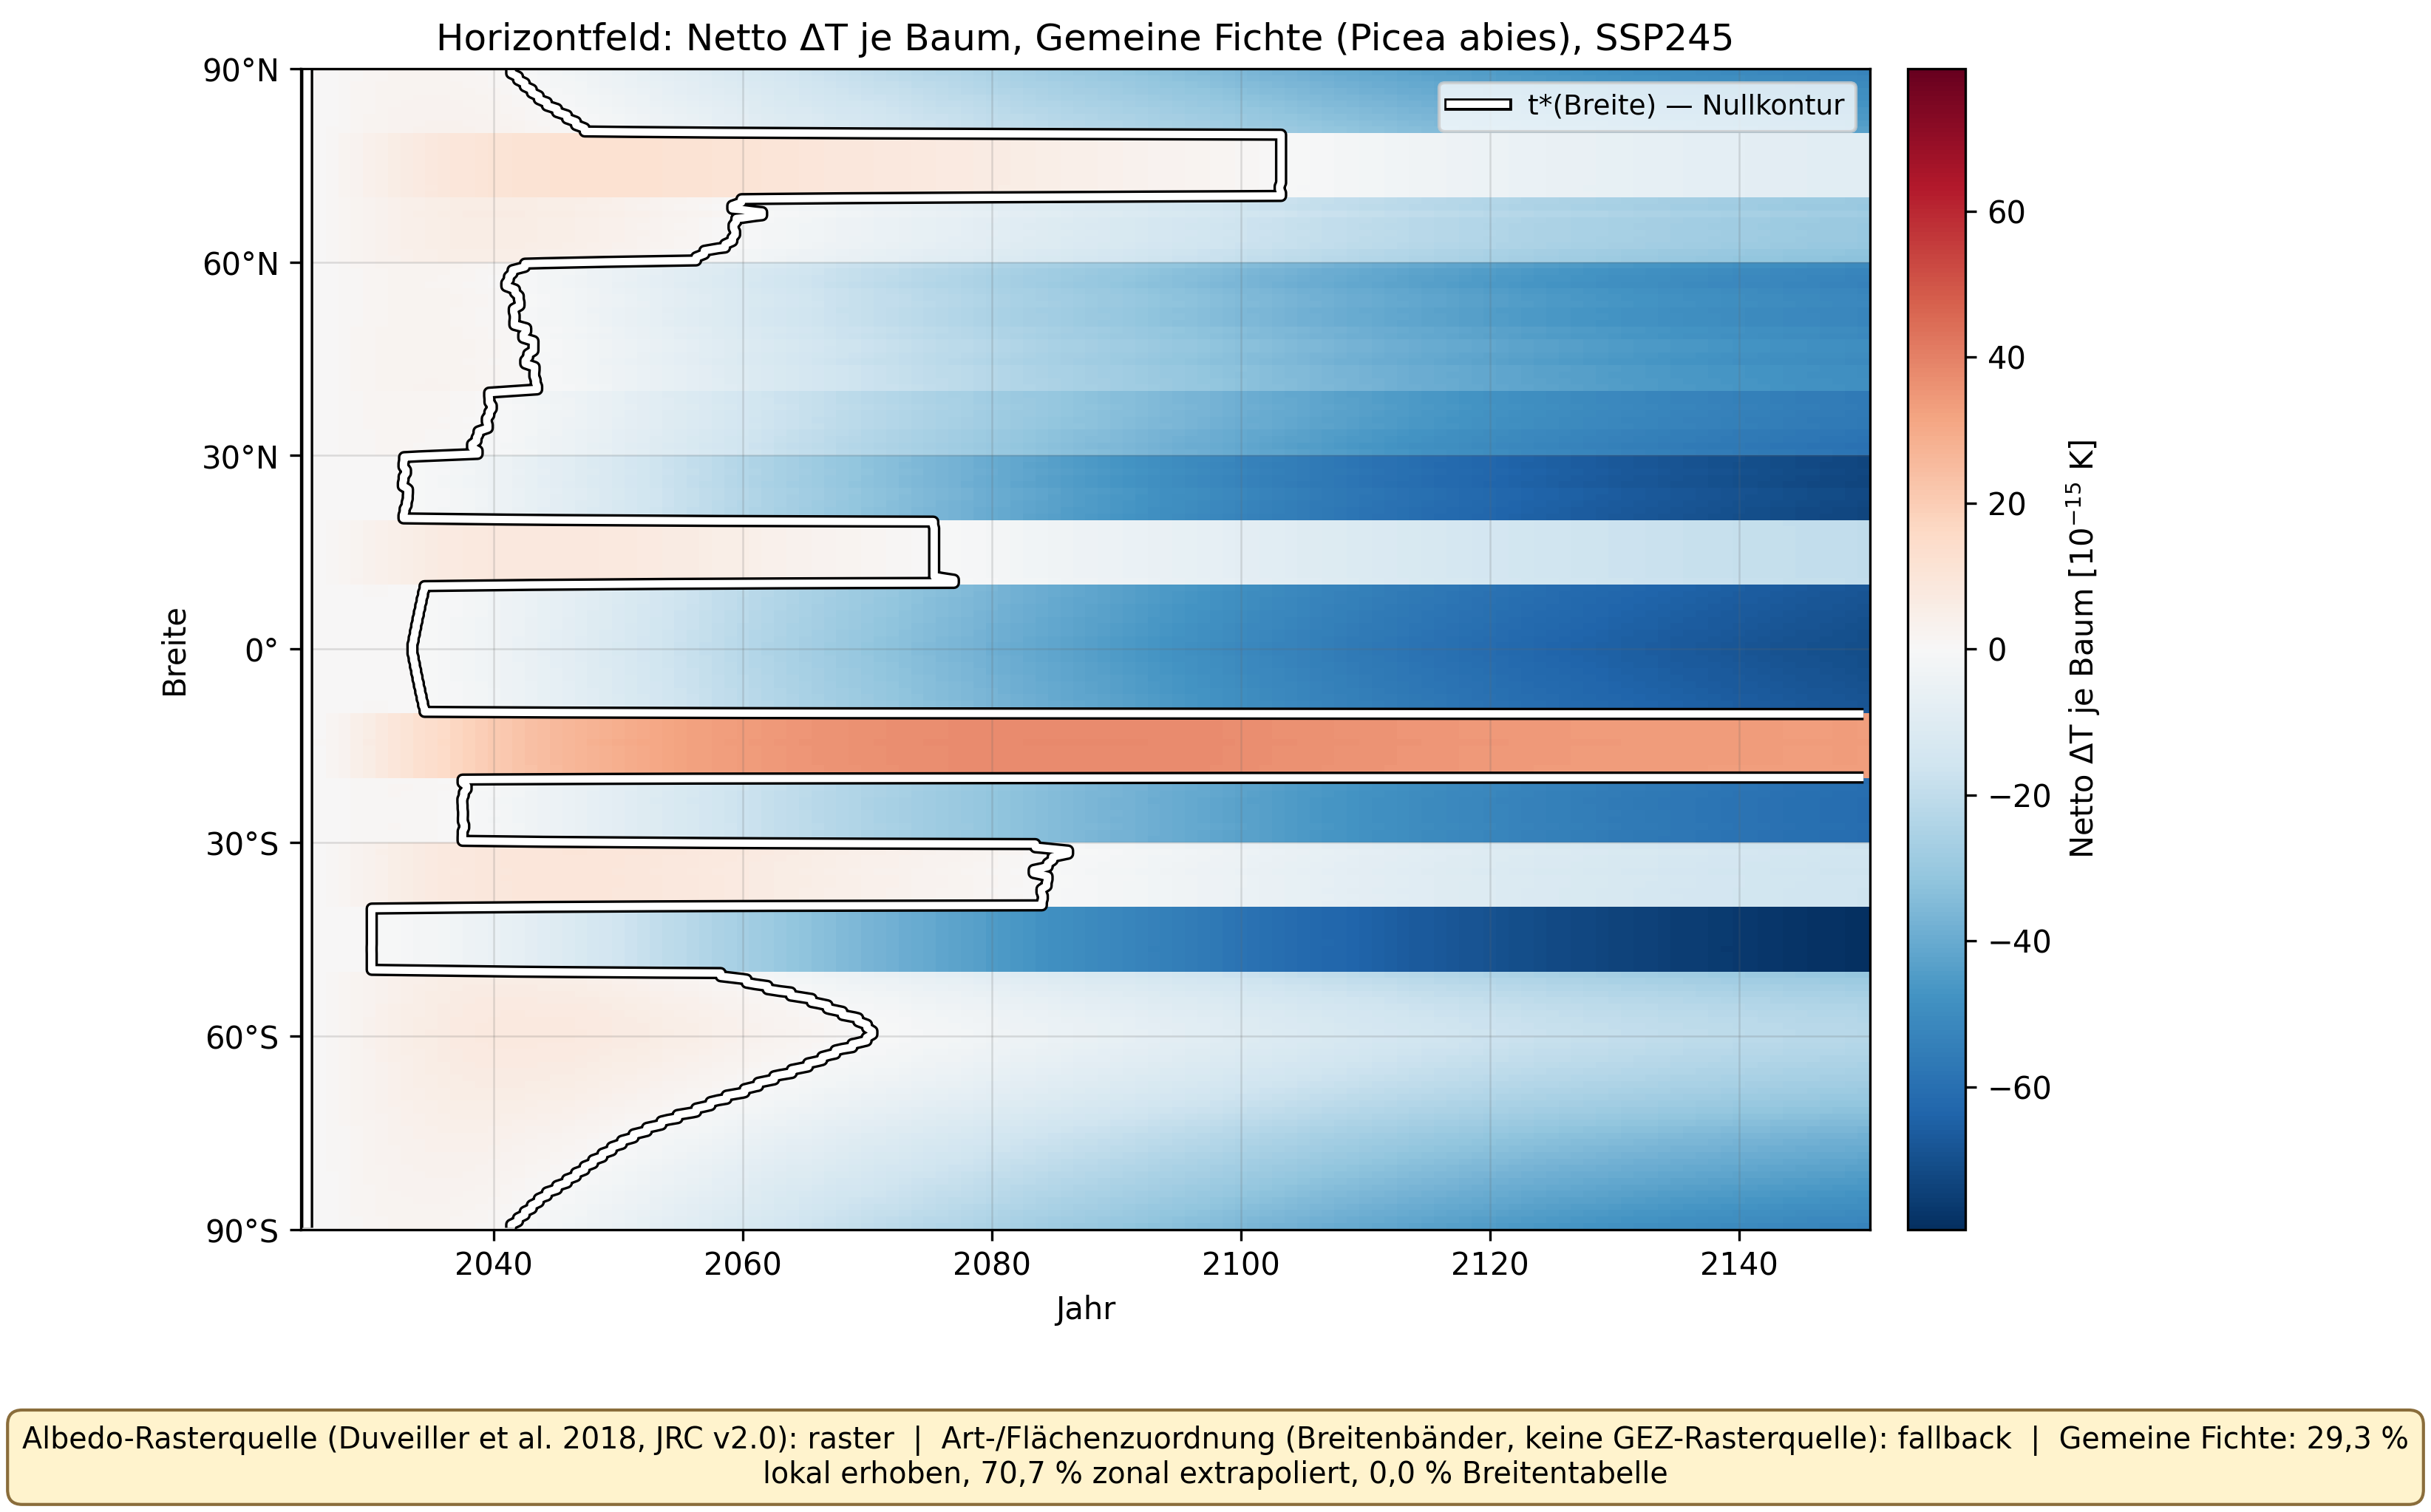

In [8]:
e6 = plot_horizon_field(f"{FIG}/e6_horizontfeld.png", species_key="enf_boreal")
display(Image(e6))

**Sichtprüfung:** Die weiße Nullkontur trennt sichtbar zwei wärmende
Bänder nahe den Polen von einem breiten kühlenden Mittelfeld sowie einem
schmalen, deutlich sichtbaren wärmenden Streifen in den mittleren
Südbreiten. Dieser Streifen ist kein Fehler: `plot_horizon_field` zeigt das
zonal gemittelte Fichte-Produkt für **jede** Breite, nicht nur für das
Band, in dem die Fichte tatsächlich gepflanzt wird (60--70° N/S) -- die
Abbildung beantwortet "was wäre, wenn dort Fichte stünde", nicht "wo steht
die Fichte". Innerhalb des tatsächlichen Pflanzbandes liegt die
Nullkontur früh im Jahrhundert, konsistent mit der Einzelbaum-Kette aus
Notebook 01.

## 4. Die Kaskade

Akt 6: Bastins unkorrigierter Rohwert, zwei reine Literaturkorrekturen
(Bodenkohlenstoff, keine Modellrechnung dieses Projekts), dann drei
Stufen, die **dieses Modell** selbst rechnet -- Landmaske, Albedo-Filter,
Störungspuffer.

In [9]:
steps = cascade()
df_cascade = pd.DataFrame(steps)[["name_de", "area_gha", "carbon_gtc", "delta_t_2150", "quelle"]]
df_cascade.columns = ["Stufe", "Fläche [Gha]", "Kohlenstoff [GtC]", "ΔT(2150) [K]", "Quelle"]
df_cascade

,Stufe,Fläche [Gha],Kohlenstoff [GtC],ΔT(2150) [K],Quelle
0,"Bastin, Rohwert",NaN,205.000000,NaN,"Bastin, J.-F. et al. (2019), ""The global tree ..."
1,Realistische Kohlenstoffdichten und Bodenkohle...,NaN,81.000000,NaN,Veldman et al. 2019 (doi:10.1126/science.aay79...
2,Nicht-Wald-Biome ausgeschlossen,0.948807,81.000000,-0.242478,nbs.landscape.plantable_area_m2 (dieses Modell)
3,Albedo-Filter: kein Ausgleich bis zum Horizont,0.931343,79.509113,-0.243169,nbs.map_plots._breakeven_year_field (dieses Mo...
4,Störungspuffer aus dem Ensemble,0.931343,78.233147,-0.239267,nbs.pipeline.run_single_tree_ensemble (dieses ...
5,Nutzbares Potenzial,0.931343,78.233147,-0.239267,Kaskadenergebnis dieses Moduls


Die ersten beiden Stufen tragen bewusst kein Modellergebnis: `area_gha`
und `delta_t_2150` sind `None`, weil dieses Modell keinen
Bodenkohlenstoff-Term rechnet (Design-Spec Abschnitt 4/14) -- die
81-GtC-Zahl ist aus den Science-Kommentaren zu Bastin et al. 2019
übernommen (Veldman et al., Friedlingstein et al.), nicht selbst
hergeleitet, und ihre exakte Primärquelle blieb hinter einer Bezahlschranke
ungeprüft (siehe `nbs.potential`-Moduldokstring und task-7-report.md
Abschnitt 7.1). Erst ab Stufe 3 rechnet dieses Notebook die Zahlen selbst.
Die vollständige Begründung jeder Stufe steht in ihrem `note`-Feld:

In [10]:
for s in steps:
    print(f"[{s['name_de']}]")
    print(" ", s["note"])
    print()

[Bastin, Rohwert]
  Unkorrigierte Angabe aus Bastin et al. 2019: 0.9 Gha zusätzliche Kronenbedeckung (517 Mrd. Bäume), 205 GtC Kohlenstoffspeicherpotenzial bei voller Reife. Geprüft am 2026-09-10 gegen die Veröffentlichung und mehrere unabhängige Sekundärquellen -- Titel und beide Zahlen bestätigt.

[Realistische Kohlenstoffdichten und Bodenkohlenstoff]
  Literaturkorrektur, NICHT vom Modell gerechnet (die Kette hat keinen Bodenkohlenstoff-Term, Design-Spec Abschnitt 4/14). Quelle: Science-Kommentare zu Bastin et al. 2019 (Veldman et al., doi:10.1126/science.aay7976; Friedlingstein et al., doi:10.1126/science.aay8060) argumentieren, 205 GtC seien rund fünffach zu hoch; 81 GtC (rund 39 %) wird in der Sekundärliteratur wiederholt als Korrekturwert genannt und liegt neben einer unabhängigen frei zugänglichen Schätzung von 71,7-75,7 GtC (bioRxiv 10.1101/730325). Die genaue Primärquelle der Zahl 81 GtC selbst konnte wegen Paywall nicht im Volltext geprüft werden -- als unbelegt im Volltext 

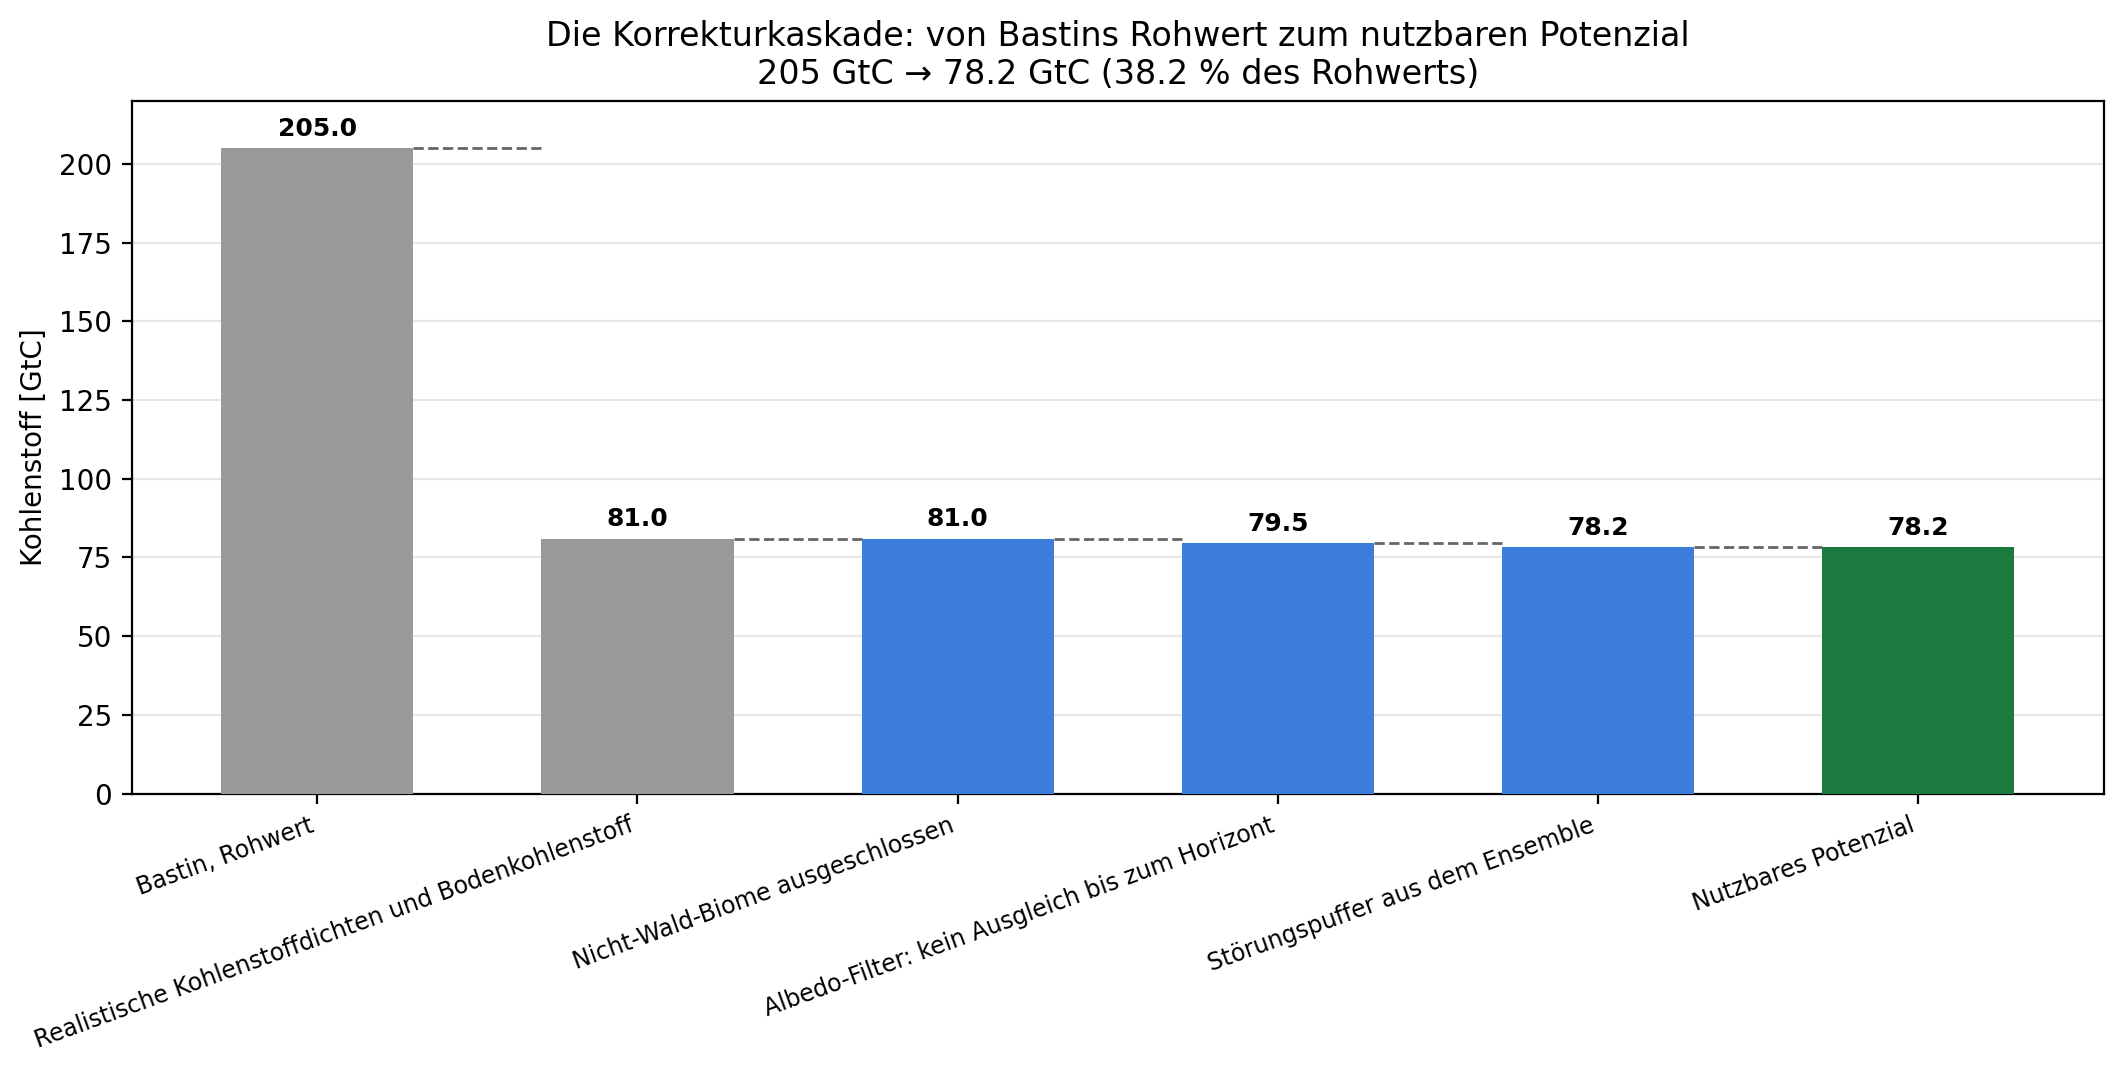

In [11]:
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(steps))
lit_mask = [s["area_gha"] is None for s in steps]
carbon = [s["carbon_gtc"] for s in steps]
colors = ["#999999" if lit else "#3b7dd8" for lit in lit_mask]
colors[-1] = "#1b7a3d"
prev = None
for i, (val, c) in enumerate(zip(carbon, colors)):
    ax.bar(i, val, color=c, width=0.6, zorder=3)
    ax.text(i, val + 4, f"{val:.1f}", ha="center", fontsize=9, fontweight="bold")
    if prev is not None:
        ax.plot([i - 1 + 0.3, i - 0.3], [prev, prev], color="0.4", lw=1.0, ls="--", zorder=2)
    prev = val
ax.set_xticks(x)
ax.set_xticklabels([s["name_de"] for s in steps], rotation=20, ha="right", fontsize=8.5)
ax.set_ylabel("Kohlenstoff [GtC]")
ax.set_ylim(0, 220)
ax.grid(axis="y", alpha=0.3)
ax.set_title(
    "Die Korrekturkaskade: von Bastins Rohwert zum nutzbaren Potenzial\n"
    f"{carbon[0]:.0f} GtC → {carbon[-1]:.1f} GtC ({100 * carbon[-1] / carbon[0]:.1f} % des Rohwerts)"
)
fig.tight_layout()
path2 = f"{FIG}/p2_kaskade_wasserfall.png"
fig.savefig(path2, dpi=200, bbox_inches="tight")
plt.close(fig)
display(Image(path2))

**Was auffällt:** Der große Sprung liegt bei der Literaturkorrektur
(205 → 81 GtC, −60 %), nicht bei den drei modellgerechneten Stufen (81 →
78,2 GtC, weitere −3,4 %). Landmaske, Albedo-Filter und Störungspuffer
verfeinern eine bereits stark korrigierte Zahl -- sie erfinden die
Korrektur nicht neu. Das nutzbare Potenzial: **78,2 GtC** (Band
69,8--84,7 GtC), auf **0,9313 Gha**, entsprechend **38,2 %** von Bastins
unkorrigiertem Rohwert, bei **0,2393 K** globaler Abkühlung 2150 unter
SSP245 (Zahlen aus der Tabelle und dem letzten `note`-Feld oben, nicht neu
gerechnet).

## 5. Die Umkehrrechnung

Wie viele Vielfache der von diesem Modell identifizierten, korrigierten
Art-/Flächenmischung (0,9488 Gha) wären nötig, um SSP245 ab 2050 unter
1,5 °C zu bringen und dort zu halten? Zwei Varianten: das volle Modell
(CO₂ + Albedo + Störung) gegen eine reine Kohlenstoffrechnung (kein
Albedo-Kanal, keine Störung). Beide Varianten lesen dieselbe Art-/
Flächenmischung wie Abschnitt 1 -- ungefiltert von den Albedo- und
Störungsstufen der Kaskade, die breiteste ehrliche Grundlage zum
Skalieren.

In [12]:
r = reverse_1p5()
for name in ("mit_albedo_und_stoerung", "nur_kohlenstoff"):
    v = r[name]
    print(f"{name}:")
    print(f"  Vielfaches der Modellfläche: {v['vielfaches_der_modellierten_flaeche']:.2f}x")
    print(f"  Fläche:                      {v['area_gha']:.2f} Gha")
    print(f"  Bäume:                       {v['n_trees']:.3e}")
    print(f"  kritisches Jahr:             {v['kritisches_jahr']}")
    print()
print(f"Verhältnis (volles Modell / nur Kohlenstoff): {r['verhaeltnis']:.3f}")
print()
print(r["hinweis"])

mit_albedo_und_stoerung:
  Vielfaches der Modellfläche: 10.28x
  Fläche:                      9.76 Gha
  Bäume:                       1.976e+13
  kritisches Jahr:             2149

nur_kohlenstoff:
  Vielfaches der Modellfläche: 10.10x
  Fläche:                      9.58 Gha
  Bäume:                       1.942e+13
  kritisches Jahr:             2149

Verhältnis (volles Modell / nur Kohlenstoff): 1.018

Beide Varianten liegen bereits über dem Vielfachen der von diesem Modell identifizierten bepflanzbaren Fläche (0.949 Gha) -- 10.3-fach mit Albedo und Störung, 10.1-fach bei reiner Kohlenstoffrechnung. Das ist größer als die gesamte eisfreie Landfläche der Erde: Baumpflanzung allein hält ssp245 nicht unter 1,5 Grad.


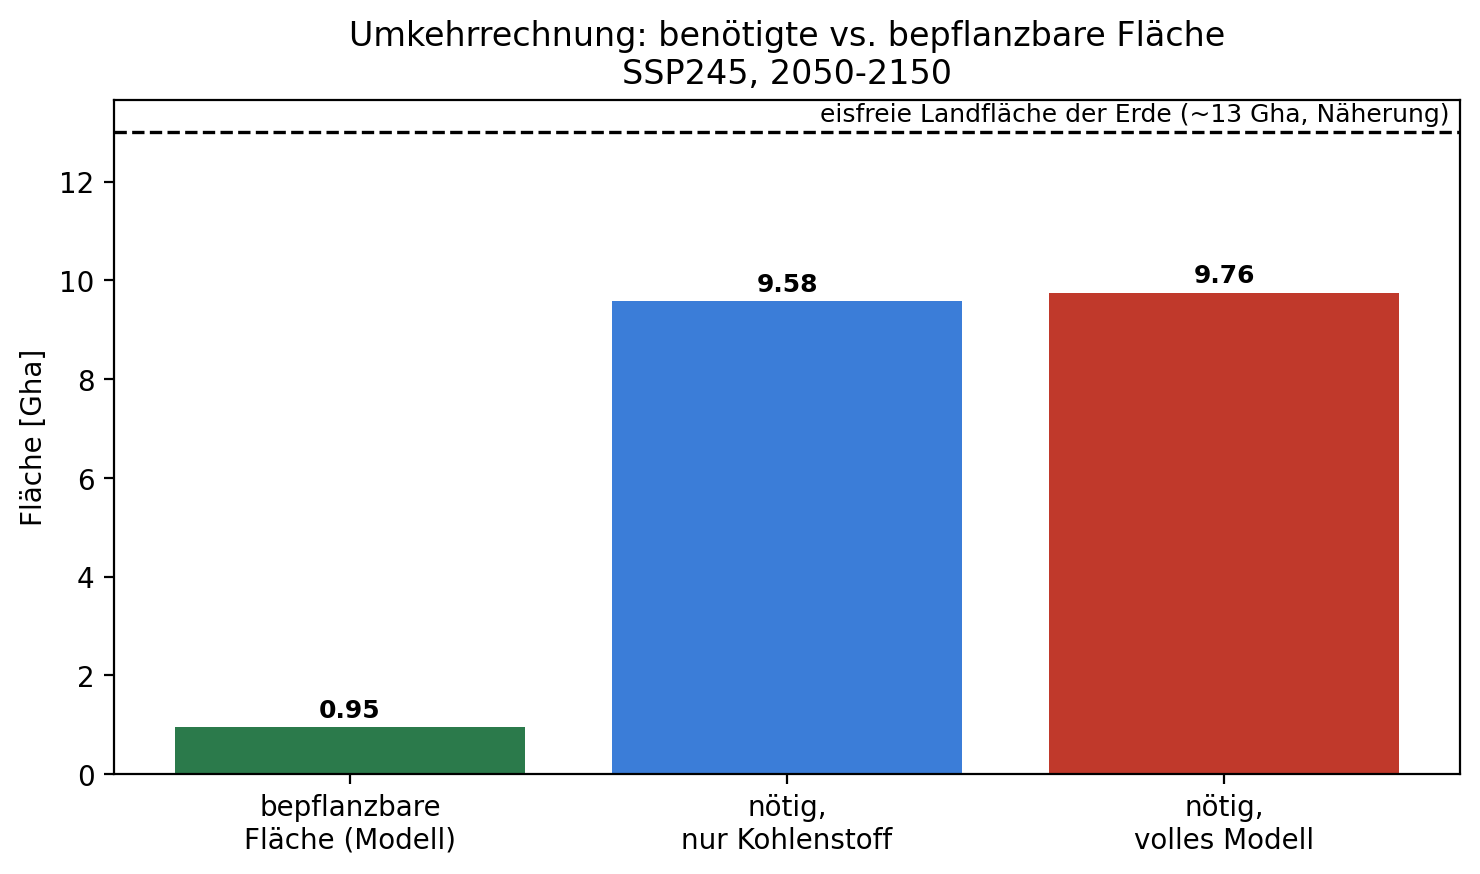

In [13]:
ICE_FREE_LAND_GHA = 13.0  # gerundete literaturübliche Näherung, nicht aus diesem Modell gerechnet

fig, ax = plt.subplots(figsize=(7.5, 4.5))
labels = ["bepflanzbare\nFläche (Modell)", "nötig,\nnur Kohlenstoff", "nötig,\nvolles Modell"]
values = [area_gha, r["nur_kohlenstoff"]["area_gha"], r["mit_albedo_und_stoerung"]["area_gha"]]
colors2 = ["#2b7a4b", "#3b7dd8", "#c0392b"]
ax.bar(labels, values, color=colors2)
ax.axhline(ICE_FREE_LAND_GHA, color="black", ls="--", lw=1.2)
ax.annotate(
    f"eisfreie Landfläche der Erde (~{ICE_FREE_LAND_GHA:.0f} Gha, Näherung)",
    xy=(1, ICE_FREE_LAND_GHA), xycoords=("axes fraction", "data"),
    xytext=(-4, 4), textcoords="offset points", ha="right", fontsize=9,
)
ax.set_ylabel("Fläche [Gha]")
ax.set_title("Umkehrrechnung: benötigte vs. bepflanzbare Fläche\nSSP245, 2050-2150")
for i, v in enumerate(values):
    ax.text(i, v + 0.2, f"{v:.2f}", ha="center", fontsize=9, fontweight="bold")
fig.tight_layout()
path3 = f"{FIG}/p4_umkehrrechnung.png"
fig.savefig(path3, dpi=200, bbox_inches="tight")
plt.close(fig)
display(Image(path3))

**Was die Zahl bedeutet:** Beide Varianten liegen bei rund dem
Zehnfachen der von diesem Modell identifizierten bepflanzbaren Fläche --
mehr als die gesamte eisfreie Landfläche der Erde. Baumpflanzung allein
hält SSP245 nicht unter 1,5 °C, selbst wenn jede identifizierte
bepflanzbare Zelle mehrfach überplant würde. Das volle Modell (mit
Albedo-Kanal und Störungspuffer) braucht durchweg mehr Fläche als die
reine Kohlenstoffrechnung -- der Unterschied ist bei diesem global
gemischten Artenportfolio mit rund 2 % moderat, weil sich borealer
Erwärmungsanteil und tropischer/gemäßigter Kühlungsvorteil in der
Flächensumme teilweise ausgleichen.

Das ist keine Modellschwäche, sondern die erwartete Schlussfolgerung eines
Vortrags, der die Bastin-Kritik nachvollzieht: Aufforstung ist ein
Baustein, kein Ersatz für Emissionsminderung.

## Offen

- Ackerland als alternative Ausgangsvegetation (Variante vorgesehen, nicht
  ausgebaut).
- Kein Erdsystemmodell: bei kontinentaler Aufforstung verschiebt sich Λ,
  und die Emulator-Näherung trägt nicht mehr -- für die Kaskade als Grenze
  zu benennen, nicht zu beheben.
- Die pptx-Übernahme dieser Abbildungen und Zahlen ist Plan 3.